In [52]:
import pandas as pd

# Chemin du fichier
file_path = '/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/dataset.tp2.xlsx'

# Chargement du fichier Excel
df = pd.read_excel(file_path)

# Affichage des premières lignes
display(df.head(10))

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
0,NaN,Arrangement,Date 4/,Agreed,Drawn,Outstanding
1,Standby Arrangement,"Dec 01, 2025","Nov 30, 2028",128.8,0,0
2,Standby Arrangement,"Dec 12, 2022","Nov 30, 2025",128.8,0,0
3,Standby Arrangement,"May 17, 2019","May 03, 2022",308.8,308.8,38.572
4,Extended Fund Facility,"Mar 07, 2014","Jun 27, 2017",82.21,82.21,7.835
5,Extended Credit Facility,"Jun 28, 2010","Jul 02, 2013",133.4,133.4,0
6,Extended Fund Facility,"Jun 28, 2010","Jun 24, 2013",133.4,133.4,0
7,Standby Arrangement,"Mar 06, 2009","Jun 27, 2010",533.6,350.425,0
8,Extended Credit Facility,"Nov 17, 2008","Mar 06, 2009",9.2,1.31,0
9,Extended Credit Facility,"May 25, 2005","May 23, 2008",23,23,0


In [53]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [54]:
# Sélection des données de l'index 3 à l'index 7 inclus
df_subset = df.loc[3:7]

# Affichage de l'extrait
display(df_subset)

,Facility,Date of,Expiration,Amount,Amount.1,Amount.2
3,Standby Arrangement,"May 17, 2019","May 03, 2022",308.8,308.8,38.572
4,Extended Fund Facility,"Mar 07, 2014","Jun 27, 2017",82.21,82.21,7.835
5,Extended Credit Facility,"Jun 28, 2010","Jul 02, 2013",133.4,133.4,0
6,Extended Fund Facility,"Jun 28, 2010","Jun 24, 2013",133.4,133.4,0
7,Standby Arrangement,"Mar 06, 2009","Jun 27, 2010",533.6,350.425,0


In [55]:
# Lecture des instructions des exercices
with open('/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/Prompt_TP_Colab_SQL.md', 'r', encoding='utf-8') as file:
    instructions = file.read()

print(instructions[:3000])  # Afficher les 3000 premiers caractères

# Prompt : Conception d'un TP universitaire – Acquisition, stockage et exploitation de données avec Google Colab et SQL

## 1. Contexte pédagogique

Agis en tant qu'enseignant-chercheur spécialisé en informatique, bases de données et analyse de données.

Conçois un **travail pratique (TP) complet, progressif et réalisable sur Google Colab**, destiné à des étudiants universitaires découvrant l'intégration de Python, Google Drive et SQL dans un projet d'analyse de données.

Le TP doit être organisé autour d'un **mini-projet concret**, fondé sur l'exploitation d'un jeu de données réel.

**Principe pédagogique :** les étudiants doivent réaliser eux-mêmes les différentes étapes. Le document doit donc présenter des consignes, des questions, des indications et des espaces de réponse, sans fournir immédiatement toutes les solutions.

## 2. Objectifs pédagogiques

À l'issue du TP, les étudiants devront être capables de :

1. Rechercher et sélectionner un jeu de données public pertinent.
2. Télé

In [56]:
import pandas as pd
from google.colab import drive

# 1. Montage de Google Drive si ce n'est pas déjà fait
try:
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive monté avec succès !")
except Exception as e:
    print("Erreur lors du montage du Drive :", e)

# 2. Chargement du fichier Excel
file_path = '/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/dataset.tp2.xlsx'
try:
    df = pd.read_excel(file_path)
    print("Données brutes chargées avec succès.")

    # 3. Nettoyage (Partie 3 du TP)
    df_cleaned = df.copy()
    df_cleaned.columns = ['Facility', 'Date_of_Arrangement', 'Expiration_Date', 'Amount_Agreed', 'Amount_Drawn', 'Amount_Outstanding']

    # Suppression de la première ligne d'en-têtes secondaires
    df_cleaned = df_cleaned.drop(index=0).reset_index(drop=True)

    # Conversion des montants
    for col in ['Amount_Agreed', 'Amount_Drawn', 'Amount_Outstanding']:
        df_cleaned[col] = df_cleaned[col].astype(str).str.replace(',', '')
        df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors='coerce')

    # Conversion des dates
    df_cleaned['Date_of_Arrangement'] = pd.to_datetime(df_cleaned['Date_of_Arrangement'], errors='coerce')
    df_cleaned['Expiration_Date'] = pd.to_datetime(df_cleaned['Expiration_Date'], errors='coerce')

    print("\n--- PARTIE 3 : Aperçu des données nettoyées ---")
    print(df_cleaned.info())
    display(df_cleaned.head())
except Exception as e:
    print("Erreur lors de la lecture ou de la préparation des données :", e)

Mounted at /content/drive
Google Drive monté avec succès !
Données brutes chargées avec succès.

--- PARTIE 3 : Aperçu des données nettoyées ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Facility             13 non-null     object        
 1   Date_of_Arrangement  12 non-null     datetime64[ns]
 2   Expiration_Date      12 non-null     datetime64[ns]
 3   Amount_Agreed        13 non-null     float64       
 4   Amount_Drawn         13 non-null     float64       
 5   Amount_Outstanding   13 non-null     float64       
dtypes: datetime64[ns](2), float64(3), object(1)
memory usage: 756.0+ bytes
None


,Facility,Date_of_Arrangement,Expiration_Date,Amount_Agreed,Amount_Drawn,Amount_Outstanding
0,Standby Arrangement,2025-12-01,2028-11-30,128.80,0.00,0.000
1,Standby Arrangement,2022-12-12,2025-11-30,128.80,0.00,0.000
2,Standby Arrangement,2019-05-17,2022-05-03,308.80,308.80,38.572
3,Extended Fund Facility,2014-03-07,2017-06-27,82.21,82.21,7.835
4,Extended Credit Facility,2010-06-28,2013-07-02,133.40,133.40,0.000


In [57]:
# PARTIE 4 – Création de la base de données SQLite et chargement des données
import sqlite3

# 1. Connexion à la base de données SQLite (elle sera créée si elle n'existe pas)
conn = sqlite3.connect('imf_data.db')

# 2. Exportation du DataFrame nettoyé vers la table SQL 'arrangements'
# index=False évite de stocker l'index du DataFrame comme une colonne SQL
df_cleaned.to_sql('arrangements', conn, if_exists='replace', index=False)
print("La table 'arrangements' a été créée et chargée avec succès dans 'imf_data.db'!")

# 3. Vérification rapide en interrogeant la base de données en SQL
query_verify = "SELECT COUNT(*) as total_rows FROM arrangements;"
df_verify = pd.read_sql_query(query_verify, conn)

print("\nVérification SQL de la table :")
display(df_verify)

# Fermeture de la connexion temporaire
conn.close()

La table 'arrangements' a été créée et chargée avec succès dans 'imf_data.db'!

Vérification SQL de la table :


,total_rows
0,13


In [58]:
# Lecture approfondie des instructions pour la Partie 5 (Exercices SQL)
with open('/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/Prompt_TP_Colab_SQL.md', 'r', encoding='utf-8') as f:
    instructions_completes = f.read()

# Recherche des exercices SQL (Partie 5)
if "Partie 5" in instructions_completes:
    idx_part5 = instructions_completes.find("Partie 5")
    print(instructions_completes[idx_part5:idx_part5+4000])
else:
    print("Partie 5 non trouvée explicitement, voici un extrait global des instructions :")
    print(instructions_completes[:3000])

Partie 5 – Exploitation du dataset avec SQL

Construire une série de 15 exercices SQL de difficulté progressive.

**Niveau 1 – Requêtes fondamentales**

1. Afficher toutes les observations.
2. Sélectionner certaines colonnes.
3. Limiter le nombre de résultats.
4. Trier les observations.
5. Filtrer les données avec `WHERE`.

**Niveau 2 – Agrégations**

6. Calculer le nombre total d'enregistrements.
7. Calculer une moyenne.
8. Déterminer les valeurs minimale et maximale.
9. Regrouper les observations avec `GROUP BY`.
10. Filtrer les groupes avec `HAVING`.

**Niveau 3 – Analyses avancées**

11. Combiner plusieurs conditions avec `AND` et `OR`.
12. Utiliser `BETWEEN` ou `IN`.
13. Réaliser un classement avec `ORDER BY`.
14. Construire une sous-requête SQL.
15. Produire une analyse synthétique répondant à une question métier ou économique.

Les requêtes doivent être adaptées aux colonnes réellement présentes dans le dataset choisi.

### Partie 6 – Analyse et interprétation

Demander aux étud

In [59]:
# PARTIE 5 – Exécution des 15 requêtes SQL progressives (Corrigé)
import sqlite3
import pandas as pd

# Reconnexion à la base de données SQLite
conn = sqlite3.connect('imf_data.db')

def executer_requete(titre, query):
    print("="*80)
    print(f"{titre}")
    print("="*80)
    print(f"Requête SQL :\n{query}\n")
    df_res = pd.read_sql_query(query, conn)
    display(df_res)
    print("\n")

# --- NIVEAU 1 : Requêtes fondamentales ---

# 1. Afficher toutes les observations
executer_requete(
    "1. Afficher toutes les observations",
    "SELECT * FROM arrangements;"
)

# 2. Sélectionner certaines colonnes
executer_requete(
    "2. Sélectionner certaines colonnes (Facility, Date_of_Arrangement, Amount_Agreed)",
    "SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements;"
)

# 3. Limiter le nombre de résultats
executer_requete(
    "3. Limiter le nombre de résultats aux 5 premières lignes",
    "SELECT * FROM arrangements LIMIT 5;"
)

# 4. Trier les observations
executer_requete(
    "4. Trier les observations par Amount_Agreed (ordre décroissant)",
    "SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements ORDER BY Amount_Agreed DESC;"
)

# 5. Filtrer les données avec WHERE
executer_requete(
    "5. Filtrer les données avec WHERE (Standby Arrangement uniquement)",
    "SELECT * FROM arrangements WHERE Facility = 'Standby Arrangement';"
)

# --- NIVEAU 2 : Agrégations ---

# 6. Calculer le nombre total d'enregistrements
executer_requete(
    "6. Calculer le nombre total d'enregistrements",
    "SELECT COUNT(*) AS Total_Accords FROM arrangements;"
)

# 7. Calculer une moyenne
executer_requete(
    "7. Calculer le montant moyen accordé (Amount_Agreed)",
    "SELECT AVG(Amount_Agreed) AS Moyenne_Montant_Accorde FROM arrangements;"
)

# 8. Déterminer les valeurs minimale et maximale
executer_requete(
    "8. Déterminer les montants accordés minimum et maximum",
    "SELECT MIN(Amount_Agreed) AS Montant_Min, MAX(Amount_Agreed) AS Montant_Max FROM arrangements;"
)

# 9. Regrouper les observations avec GROUP BY
executer_requete(
    "9. Regrouper les observations par type de Facility et compter le nombre d'accords",
    "SELECT Facility, COUNT(*) AS Nombre_Accords, SUM(Amount_Agreed) AS Total_Accorde FROM arrangements GROUP BY Facility;"
)

# 10. Filtrer les groupes avec HAVING
executer_requete(
    "10. Filtrer pour n'afficher que les types de Facility ayant au moins 2 accords",
    "SELECT Facility, COUNT(*) AS Nombre_Accords FROM arrangements GROUP BY Facility HAVING COUNT(*) >= 2;"
)

# --- NIVEAU 3 : Analyses avancées ---

# 11. Combiner plusieurs conditions avec AND et OR
executer_requete(
    "11. Accords signés après 2015 ET avec un montant supérieur à 100 000",
    "SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements WHERE Date_of_Arrangement > '2015-01-01' AND Amount_Agreed > 100000;"
)

# 12. Utiliser BETWEEN ou IN
executer_requete(
    "12. Accords dont la date de signature est comprise entre 2010 et 2020 included",
    "SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements WHERE Date_of_Arrangement BETWEEN '2010-01-01' AND '2020-12-31';"
)

# 13. Réaliser un classement avec ORDER BY
executer_requete(
    "13. Classement des accords par montant restant dû (Amount_Outstanding) décroissant",
    "SELECT Facility, Date_of_Arrangement, Amount_Outstanding FROM arrangements ORDER BY Amount_Outstanding DESC;"
)

# 14. Construire une sous-requête SQL
executer_requete(
    "14. Accords dont le montant est strictement supérieur à la moyenne globale",
    "SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements WHERE Amount_Agreed > (SELECT AVG(Amount_Agreed) FROM arrangements);"
)

# 15. Produire une analyse synthétique métier / macroéconomique
executer_requete(
    "15. Synthèse économique globale par type de facilité",
    """SELECT
        Facility,
        COUNT(*) AS Nombre_Total_Accords,
        SUM(Amount_Agreed) AS Total_Accorde,
        SUM(Amount_Drawn) AS Total_Tire,
        SUM(Amount_Outstanding) AS Total_Restant_Du,
        ROUND((SUM(Amount_Drawn) / SUM(Amount_Agreed)) * 100, 2) || '%' AS Taux_Utilisation_Moyen
     FROM arrangements
     GROUP BY Facility;"""
)

conn.close()

1. Afficher toutes les observations
Requête SQL :
SELECT * FROM arrangements;



,Facility,Date_of_Arrangement,Expiration_Date,Amount_Agreed,Amount_Drawn,Amount_Outstanding
0,Standby Arrangement,2025-12-01 00:00:00,2028-11-30 00:00:00,128.800,0.000,0.000
1,Standby Arrangement,2022-12-12 00:00:00,2025-11-30 00:00:00,128.800,0.000,0.000
2,Standby Arrangement,2019-05-17 00:00:00,2022-05-03 00:00:00,308.800,308.800,38.572
3,Extended Fund Facility,2014-03-07 00:00:00,2017-06-27 00:00:00,82.210,82.210,7.835
4,Extended Credit Facility,2010-06-28 00:00:00,2013-07-02 00:00:00,133.400,133.400,0.000
5,Extended Fund Facility,2010-06-28 00:00:00,2013-06-24 00:00:00,133.400,133.400,0.000
6,Standby Arrangement,2009-03-06 00:00:00,2010-06-27 00:00:00,533.600,350.425,0.000
7,Extended Credit Facility,2008-11-17 00:00:00,2009-03-06 00:00:00,9.200,1.310,0.000
8,Extended Credit Facility,2005-05-25 00:00:00,2008-05-23 00:00:00,23.000,23.000,0.000
9,Extended Credit Facility,2001-05-23 00:00:00,2004-12-31 00:00:00,69.000,69.000,0.000




2. Sélectionner certaines colonnes (Facility, Date_of_Arrangement, Amount_Agreed)
Requête SQL :
SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements;



,Facility,Date_of_Arrangement,Amount_Agreed
0,Standby Arrangement,2025-12-01 00:00:00,128.800
1,Standby Arrangement,2022-12-12 00:00:00,128.800
2,Standby Arrangement,2019-05-17 00:00:00,308.800
3,Extended Fund Facility,2014-03-07 00:00:00,82.210
4,Extended Credit Facility,2010-06-28 00:00:00,133.400
5,Extended Fund Facility,2010-06-28 00:00:00,133.400
6,Standby Arrangement,2009-03-06 00:00:00,533.600
7,Extended Credit Facility,2008-11-17 00:00:00,9.200
8,Extended Credit Facility,2005-05-25 00:00:00,23.000
9,Extended Credit Facility,2001-05-23 00:00:00,69.000




3. Limiter le nombre de résultats aux 5 premières lignes
Requête SQL :
SELECT * FROM arrangements LIMIT 5;



...

,Facility,Date_of_Arrangement,Amount_Outstanding
0,Total,None,46.408
1,Standby Arrangement,2019-05-17 00:00:00,38.572
2,Extended Fund Facility,2014-03-07 00:00:00,7.835
3,Standby Arrangement,2025-12-01 00:00:00,0.000
4,Standby Arrangement,2022-12-12 00:00:00,0.000
5,Extended Credit Facility,2010-06-28 00:00:00,0.000
6,Extended Fund Facility,2010-06-28 00:00:00,0.000
7,Standby Arrangement,2009-03-06 00:00:00,0.000
8,Extended Credit Facility,2008-11-17 00:00:00,0.000
9,Extended Credit Facility,2005-05-25 00:00:00,0.000




14. Accords dont le montant est strictement supérieur à la moyenne globale
Requête SQL :
SELECT Facility, Date_of_Arrangement, Amount_Agreed FROM arrangements WHERE Amount_Agreed > (SELECT AVG(Amount_Agreed) FROM arrangements);



,Facility,Date_of_Arrangement,Amount_Agreed
0,Total,None,1703435.0




15. Synthèse économique globale par type de facilité
Requête SQL :
SELECT 
        Facility,
        COUNT(*) AS Nombre_Total_Accords,
        SUM(Amount_Agreed) AS Total_Accorde,
        SUM(Amount_Drawn) AS Total_Tire,
        SUM(Amount_Outstanding) AS Total_Restant_Du,
        ROUND((SUM(Amount_Drawn) / SUM(Amount_Agreed)) * 100, 2) || '%' AS Taux_Utilisation_Moyen
     FROM arrangements
     GROUP BY Facility;



,Facility,Nombre_Total_Accords,Total_Accorde,Total_Tire,Total_Restant_Du,Taux_Utilisation_Moyen
0,Total,1,1703435.000,1224395.000,46.408,71.88%
1,Extended Credit Facility,5,343.950,336.060,0.000,97.71%
2,Extended Fund Facility,2,215.610,215.610,7.835,100.0%
3,Standby Arrangement,5,1143.875,672.725,38.572,58.81%


La table SQLite 'arrangements' a été mise à jour avec exclusion stricte de la ligne de cumul 'Total'.
Nouveau nombre d'accords réels enregistrés : 12

########################################
# PARTIE 6 : SÉLECTION & VISUALISATIONS (CORRIGÉES)
########################################



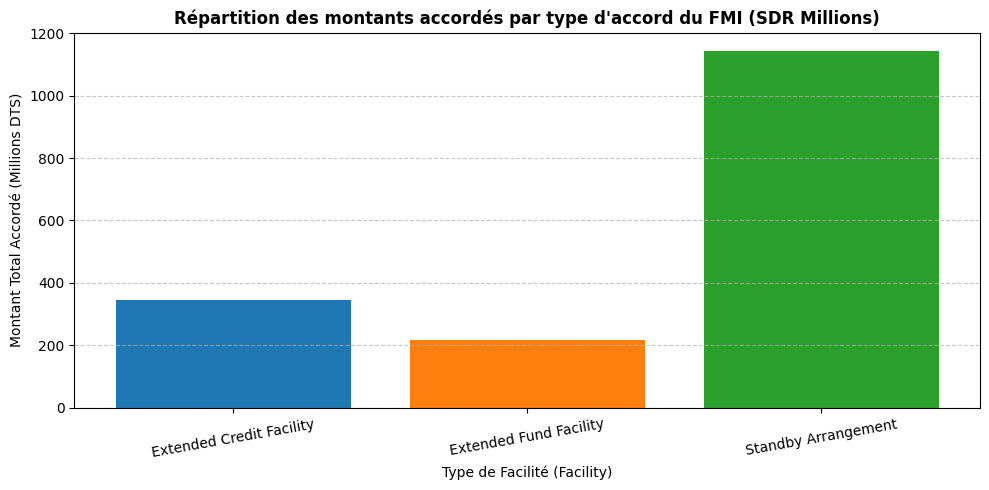

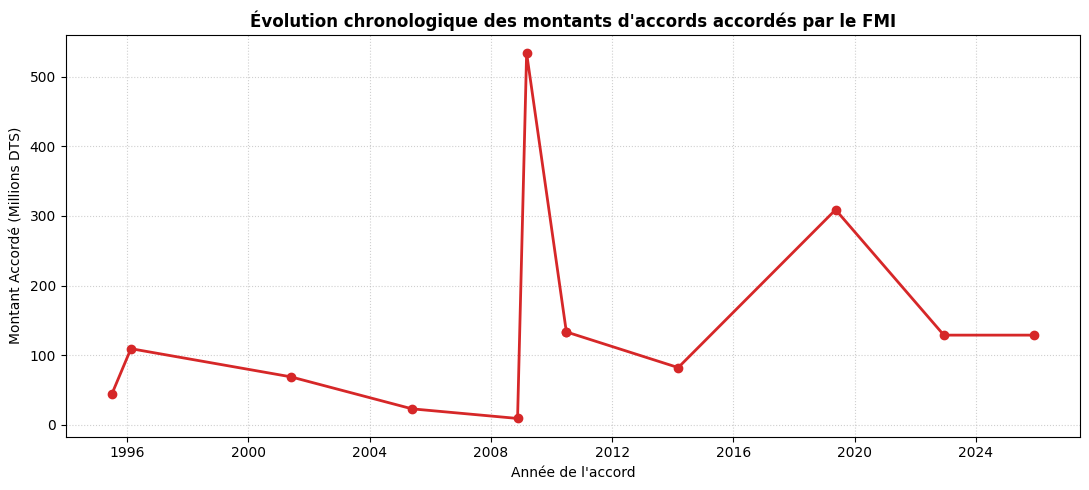


--- TABLEAU DE SYNTHÈSE ÉCONOMIQUE NETTOYÉ ET EXCLUSIF ---


,Facility,Nombre_Total_Accords,Total_Accorde,Total_Tire,Total_Restant_Du,Taux_Utilisation_Moyen_Pourcent
0,Extended Credit Facility,5,343.95,336.06,0.00,97.71
1,Extended Fund Facility,2,215.61,215.61,7.83,100.00
2,Standby Arrangement,5,1143.88,672.73,38.57,58.81


In [60]:
# Nettoyage de la base de données : suppression stricte et définitive de la ligne de cumul 'Total'
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# 1. Nettoyage strict du DataFrame Pandas d'origine
# On supprime toute ligne où la colonne 'Facility' contient 'Total' (sans distinction de casse ou d'espaces)
df_cleaned_strict = df_cleaned[~df_cleaned['Facility'].astype(str).str.strip().str.lower().str.contains('total')].copy()

# 2. Exportation propre vers la base SQLite en écrasant la table précédente
conn = sqlite3.connect('imf_data.db')
df_cleaned_strict.to_sql('arrangements', conn, if_exists='replace', index=False)

print("La table SQLite 'arrangements' a été mise à jour avec exclusion stricte de la ligne de cumul 'Total'.")

# Vérification du nombre de lignes réelles restant (doit être de 12 lignes d'accords)
df_count = pd.read_sql_query("SELECT COUNT(*) as nb_lignes FROM arrangements;", conn)
print(f"Nouveau nombre d'accords réels enregistrés : {df_count['nb_lignes'].iloc[0]}")

# --- PARTIE 6 : ANALYSE ET INTERPRÉTATION ---

print("\n" + "#"*40 + "\n# PARTIE 6 : SÉLECTION & VISUALISATIONS (CORRIGÉES)\n" + "#"*40 + "\n")

# Graphique 1 : Répartition des montants accordés par type d'accord (Facility)
query_g1 = """
SELECT Facility, SUM(Amount_Agreed) as Total_Agreed
FROM arrangements
GROUP BY Facility;
"""
df_g1 = pd.read_sql_query(query_g1, conn)

plt.figure(figsize=(10, 5))
plt.bar(df_g1['Facility'], df_g1['Total_Agreed'], color=['#1f77b4', '#ff7f0e', '#2ca02c'])
plt.title("Répartition des montants accordés par type d'accord du FMI (SDR Millions)", fontsize=12, fontweight='bold')
plt.xlabel("Type de Facilité (Facility)", fontsize=10)
plt.ylabel("Montant Total Accordé (Millions DTS)", fontsize=10)
plt.xticks(rotation=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/repartition_montants.png')
plt.show()

# Graphique 2 : Évolution temporelle des montants d'accords accordés
query_g2 = """
SELECT Date_of_Arrangement, Amount_Agreed, Facility
FROM arrangements
WHERE Date_of_Arrangement IS NOT NULL
ORDER BY Date_of_Arrangement ASC;
"""
df_g2 = pd.read_sql_query(query_g2, conn)
df_g2['Date_of_Arrangement'] = pd.to_datetime(df_g2['Date_of_Arrangement'])

plt.figure(figsize=(11, 5))
plt.plot(df_g2['Date_of_Arrangement'], df_g2['Amount_Agreed'], marker='o', linestyle='-', color='#d62728', linewidth=2)
plt.title("Évolution chronologique des montants d'accords accordés par le FMI", fontsize=12, fontweight='bold')
plt.xlabel("Année de l'accord", fontsize=10)
plt.ylabel("Montant Accordé (Millions DTS)", fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/asmaa mriouch_wissal mounir_fin3_tp2/evolution_temporelle.png')
plt.show()

# Affichage de la synthèse économique finale propre
query_synthese = """
SELECT
    Facility,
    COUNT(*) AS Nombre_Total_Accords,
    ROUND(SUM(Amount_Agreed), 2) AS Total_Accorde,
    ROUND(SUM(Amount_Drawn), 2) AS Total_Tire,
    ROUND(SUM(Amount_Outstanding), 2) AS Total_Restant_Du,
    ROUND((SUM(Amount_Drawn) / SUM(Amount_Agreed)) * 100, 2) AS Taux_Utilisation_Moyen_Pourcent
FROM arrangements
GROUP BY Facility;
"""
df_synth = pd.read_sql_query(query_synthese, conn)
print("\n--- TABLEAU DE SYNTHÈSE ÉCONOMIQUE NETTOYÉ ET EXCLUSIF ---")
display(df_synth)

conn.close()